# Sampling complexity of the LS machine on the Random Hierarchy Model

**Question (hshunt's criterion).** How many training grids `P` does the local-score (LS)
machine need before the grids it generates are **both novel** (not in the training set)
**and fully grammatical** (every production rule of the RHM satisfied at every level), and
how does that `P*` scale with the RHM parameters `(v, s, L, m)` and the window `k`?

**Answer.** There is no finite `P*`. Grammaticality and novelty are reached by the *same*
mechanism -- copying a training grid -- so they never hold together. Pushed to the regime
where grammaticality is `Theta(1)`, the cost is

$$P^* \;=\; v\, m^{\Theta\!\left(n/(s^2-1)\right)} \;=\; \exp\!\big(\Theta(n)\big),
\qquad n = s^{2L}\ \text{sites},$$

and at that window size novelty is identically 0. The LS machine extracts **no** benefit
from the hierarchy: its sampling complexity is the same as memorizing the whole
distribution. At fixed window `k`, `ln(1/success) = Theta(n / k^2)`.

Two legs, one derived and one measured:

1. **Ceiling (derivation, exact).** A `k x k` window centred on a site reaches only
   `k//2`, so it contains the aligned block of side `b` through that site only when
   `k >= 2b - 1`. Write `j* = floor(log_s((k+1)/2))` for the deepest level it can police.
   With unlimited data the machine samples the *locally valid* set, of which the grammar
   is a fraction
   `C(k) = |R_L| / |R_j*|^(s^(2(L-j*)))`, where `R_j` is the set of distinct leaf
   renderings of an aligned `s^j` block. With no word collisions
   `|R_j| = v m^((s^(2j)-1)/(s^2-1))` and this collapses to `f0^U`, with
   `f0 = m / v^(s^2-1)` and `U = (s^(2(L-j*)) - 1)/(s^2 - 1)` the number of rule
   instances above the window's reach.
2. **Cost (measurement).** Reaching that ceiling is coupon-collecting the `N_k` distinct
   `k x k` windows, so `P*(k) ~ N_k ln N_k * a^2/n`.

Both are checked below against generated samples scored by an exact grammar oracle.

## Provenance: commit, code, data

In [1]:
import json, subprocess, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'scripts'))
D = ROOT / 'results' / 'rhm_sampling' / '2026-11-02'

COMMIT = subprocess.run(['git', '-C', str(ROOT), 'rev-parse', '--short', 'HEAD'],
                        capture_output=True, text=True).stdout.strip()
load = lambda f: json.load(open(D / f))


def _fmt(c):
    if c is None:
        return '-'
    if isinstance(c, float):
        if c == int(c) and abs(c) >= 1000:
            return str(int(c))
        return f'{c:.4g}'
    return str(c)


def table(headers, rows, title=None):
    """Plain aligned text table (pandas is not in this venv)."""
    body = [[_fmt(c) for c in r] for r in rows]
    w = [max([len(h)] + [len(r[i]) for r in body]) for i, h in enumerate(headers)]
    head = '  '.join(h.rjust(w[i]) for i, h in enumerate(headers))
    if title:
        print(title)
    print(head)
    print('-' * len(head))
    for r in body:
        print('  '.join(c.rjust(w[i]) for i, c in enumerate(r)))


def agg(rows, key, cols):
    """Mean of each col over rule seeds, grouped by key(row). Skipped cells dropped."""
    g = {}
    for r in rows:
        if r.get('skipped'):
            continue
        g.setdefault(key(r), []).append(r)
    return {k: [float(np.mean([c(r) for r in v])) for c in cols] for k, v in sorted(g.items())}


print('git commit :', COMMIT)
print('data dir   :', D.relative_to(ROOT))
for p in sorted(D.glob('provenance*')):
    print(f'  {p.name:26s}', open(p).read().strip())
print()
print('code: src/utils/random_hierarchy.py  (the 2D RHM)')
print('      src/utils/rhm_grammar.py       (exact grammar + novelty oracle)')
print('      src/utils/rhm_sampling.py      (patch-count LS machine, phase-aware)')
print('      src/utils/discrete_score.py    (reveal_one ancestral sampler)')
print('      scripts/rhm_sampling_complexity.py / rhm_patch_counts.py / rhm_ceiling_exact.py')
print('jobs: 50859790 (counts), 50861030 (sweep2), 50861297 (ceiling; L=4 stage OOM, '
      'optional endpoints only)')

git commit : 
data dir   : results/rhm_sampling/2026-11-02
  provenance.txt             2ec129c
  provenance_ceiling.txt     bdf694d
  provenance_report.txt      bdf694d
  provenance_sweep.txt       2ec129c
  provenance_sweep2.txt      2ec129c

code: src/utils/random_hierarchy.py  (the 2D RHM)
      src/utils/rhm_grammar.py       (exact grammar + novelty oracle)
      src/utils/rhm_sampling.py      (patch-count LS machine, phase-aware)
      src/utils/discrete_score.py    (reveal_one ancestral sampler)
      scripts/rhm_sampling_complexity.py / rhm_patch_counts.py / rhm_ceiling_exact.py
jobs: 50859790 (counts), 50861030 (sweep2), 50861297 (ceiling; L=4 stage OOM, optional endpoints only)


### Config and seeds

Rule seed `rs` means `RandomHierarchyModel2D(v, s, L, m, seed=1000 + rs)`; every number
below is a mean over the rule seeds listed. The training set for a cell is drawn with
seed `7_000_000 + 1000*rs + P` and generation uses `manual_seed(that + 9973)`.
`T` is the number of reverse steps, `2n` by default. `align=2` is the phase-aware machine
(patches indexed by their offset within the `s x s` block); `align=1` pools all offsets,
which is what the repo's own `LocalDiscreteScoreMachine` does.

In [2]:
rows = []
for f in sorted(D.glob('*.json')):
    rs = load(f.name)
    if 'n_gen' not in rs[0]:
        continue
    u = lambda key: sorted({r[key] for r in rs})
    nsk = sum(bool(r.get('skipped')) for r in rs)
    rows.append([f.name, u('v'), u('L'), u('m'), u('k'), len(u('rule_seed')),
                 rs[0]['n_gen'], rs[0]['nsteps'], rs[0]['alpha_smooth'],
                 rs[0]['block_align'], rs[0]['pad_mode'],
                 f"{min(u('P'))}-{max(u('P'))}", nsk])
table(['file', 'v', 'L', 'm', 'k', 'seeds', 'n_gen', 'T', 'alpha', 'align', 'pad',
       'P range', 'skipped'], rows)
print('\n"skipped" = cells whose patch table exceeded --max_patches 1200000 and were not run.')

                file    v    L    m          k  seeds  n_gen    T  alpha  align      pad     P range  skipped
-------------------------------------------------------------------------------------------------------------
      A1_window.json  [4]  [3]  [3]  [3, 5, 7]      2    512  128  0.001      2  outside   30-100000        6
      A2_pooled.json  [4]  [3]  [3]        [3]      2    512  128  0.001      1  outside  100-100000        0
A3_repo_machine.json  [4]  [3]  [3]        [3]      2    512  128  0.001      1    zeros  100-100000        0
    A4_memorize.json  [4]  [3]  [3]       [15]      1    512  128  0.001      1  outside    100-1000        0
           E_m2.json  [4]  [2]  [2]        [3]      3   4096   32  0.001      2  outside    30-30000        0
           E_m3.json  [4]  [2]  [3]        [3]      3   4096   32  0.001      2  outside    30-30000        0
           E_m4.json  [4]  [2]  [4]        [3]      3   4096   32  0.001      2  outside    30-30000        0
          

## Table 1 -- the window ladder at the reference grammar

`v=4, s=2, L=3, m=3`: 8x8 grids, `n = 64` sites, `|R_L| = 4 * 3^21 = 4.2e10` grammatical
grids. `k=15 = 2d-1` is the full-window memorization control.

The identity to keep in view: a training grid is necessarily grammatical, so
`not novel => grammatical`, hence **`success = grammatical + novel - 1`**. The question is
only ever whether grammaticality beats the memorization rate.

In [3]:
A = load('A1_window.json') + load('A4_memorize.json')
cols = [lambda r: r['grammatical'], lambda r: r['novel'], lambda r: r['success'],
        lambda r: r['level_parse_fraction'][1], lambda r: r['level_parse_fraction'][2],
        lambda r: r['n_distinct_patches']]
g = agg(A, lambda r: (r['k'], r['P']), cols)
table(['k', 'P', 'gram', 'novel', 'success', '4x4 ok', '2x2 ok', 'distinct patches'],
      [[k, P] + v for (k, P), v in g.items()])
print('\n"b x b ok" = fraction of aligned b x b blocks that are a legal rendering of some')
print('symbol (level_parse_fraction). "gram" is the same quantity for the whole 8x8 grid.')

 k       P       gram   novel    success     4x4 ok   2x2 ok  distinct patches
------------------------------------------------------------------------------
 3      30          0       1          0    0.02197   0.5777              1328
 3     100          0       1          0    0.05078   0.7565              3008
 3     300          0       1          0    0.08838   0.8757              5214
 3    1000          0       1          0     0.1135   0.9523              8014
 3    3000          0       1          0     0.1138   0.9791              9856
 3   10000          0       1          0     0.1191   0.9919         1.111e+04
 3   30000  0.0009766       1  0.0009766     0.1221   0.9935         1.164e+04
 3  100000          0       1          0     0.1252    0.995         1.189e+04
 5      30          0       1          0  0.0004883   0.1073              1902
 5     100          0       1          0  0.0002441   0.1259              6272
 5     300          0       1          0  0.0002441 

**What Table 1 says.**

- `k=3` (`j*=1`): grammaticality is **0 at every P from 30 to 100 000 but one**. The
  exception is a single grid out of 1024 at `P=3e4` (0.00098), which is the resolution
  floor of the sample rather than a signal -- it is gone again at `P=1e5`. Meanwhile the
  2x2 blocks the window *can* police climb 0.578 -> 0.995 and the 4x4 blocks it cannot
  stall at 0.125. The patch table is nearly saturated as well (11 890 distinct 3x3 patches
  at `P=1e5`, +7% over the last decade of `P`), so more data buys almost nothing: the
  machine has seen all but a few percent of the windows that exist. It learns exactly the
  level it can reach and stalls permanently on the one above.
- `k=5` has the same `j*=1` but a far larger table, so it is strictly **worse** than `k=3`
  at equal `P` -- more window is not more learning unless it crosses `2b-1`.
- `k=7` (`j*=2`) is the only window short of the full grid with nonzero grammaticality
  (0.021), and it *decreases* with `P`: at small `P` the table is so sparse that the
  machine copies, and copies are grammatical.
- `k=15 = 2d-1`: grammaticality 0.82-0.87 and novelty 0.13-0.18, i.e. the two are
  complements. Success 0.000-0.002, consistent with the identity and with 0.

## Table 2 -- the derived ceiling against the measured plateau

`scripts/rhm_ceiling_exact.py` computes `C(k) = |R_L| / |R_j*|^(s^(2(L-j*)))` by
enumerating `R_j` level by level with the actual (collision-prone) rules, and by Monte
Carlo where `R_L` is too large to enumerate. The closed form `f0^U` is the same quantity
when no two drawn words coincide.

In [4]:
cl3 = [r for r in load('ceiling_L3.json') if r['v'] == 4 and r['m'] == 3]
best = {}
for r in A:
    if r.get('skipped'):
        continue
    b = best.setdefault(r['k'], [0.0, 0.0])
    b[0] = max(b[0], r['grammatical'])
    b[1] = max(b[1], r['success'])
rows = []
for k in sorted({r['k'] for r in cl3}):
    rr = [r for r in cl3 if r['k'] == k]
    bg, bs = best.get(k, [None, None])
    rows.append([k, rr[0]['j_star'], rr[0]['U'],
                 float(np.mean([r['ceiling_closed'] for r in rr])),
                 float(np.mean([r['ceiling_mc'] for r in rr])), bg, bs])
table(['k', 'j*', 'U', 'f0^U closed', 'ceiling (MC)', 'max gram seen', 'max succ seen'], rows,
      'v=4 s=2 L=3 m=3, f0 = m/v^(s^2-1) = 3/64 = 0.0469, 3 rule seeds, 4e5 MC draws')

cl2 = load('ceiling_L2.json')
ex = [r for r in cl2 if r['j_star'] < r['L']]   # k = 3 and 5, both j*=1, R_L enumerated
tol = lambda r: abs(r['ceiling_exact'] - r['ceiling_closed']) <= 1e-12 * max(1, r['ceiling_exact'])
agree = [r for r in ex if tol(r)]
clean = [r for r in ex if not r['collisions']]
coll = [r for r in ex if r['collisions']]
up = sum(r['ceiling_exact'] > r['ceiling_closed'] for r in coll)
dn_top = sum(r['R']['1'] == r['R_ideal']['1']
             for r in coll if r['ceiling_exact'] < r['ceiling_closed'])
print(f'\nL=2 enumerable cases (v in 2..8, m in 2..6, 3 rule seeds, k in 3,5): {len(ex)}')
print(f'  exact == closed form          : {len(agree)}')
print(f'  rule draw had a word collision: {len(coll)}')
print(f'  agreement set IS the collision-free set: {agree == clean}')
print(f'  where they differ: ceiling moves up in {up}, down in {len(coll) - up} '
      f'({dn_top} of those have |R_1| at its collision-free value)')
for r in coll[:3]:
    print(f"    v={r['v']} m={r['m']} rs={r['rule_seed']} k={r['k']}: |R| {r['R']} vs ideal "
          f"{r['R_ideal']}  ->  exact {r['ceiling_exact']:.4g} vs closed {r['ceiling_closed']:.4g}")

v=4 s=2 L=3 m=3, f0 = m/v^(s^2-1) = 3/64 = 0.0469, 3 rule seeds, 4e5 MC draws
 k  j*  U  f0^U closed  ceiling (MC)  max gram seen  max succ seen
------------------------------------------------------------------
 3   1  5    2.263e-07     8.333e-07       0.001953       0.001953
 7   2  1      0.04688       0.04884        0.02344              0
15   3  0            1             1         0.8672       0.001953

L=2 enumerable cases (v in 2..8, m in 2..6, 3 rule seeds, k in 3,5): 150
  exact == closed form          : 70
  rule draw had a word collision: 80
  agreement set IS the collision-free set: True
  where they differ: ceiling moves up in 48, down in 32 (26 of those have |R_1| at its collision-free value)
    v=2 m=3 rs=1 k=3: |R| {'0': 2, '1': 5, '2': 321} vs ideal {'0': 2, '1': 6, '2': 486}  ->  exact 0.5136 vs closed 0.375
    v=2 m=3 rs=1 k=5: |R| {'0': 2, '1': 5, '2': 321} vs ideal {'0': 2, '1': 6, '2': 486}  ->  exact 0.5136 vs closed 0.375
    v=2 m=3 rs=2 k=3: |R| {'0': 2, '

**What Table 2 says.** The ceiling spans five decades across the three windows and the
measurement sits under it everywhere, touching it at `k=7` and `k=15`. At `k=3` the
predicted ceiling is `2e-7`, far below what 512 x 2 samples can resolve, which is exactly
why the k=3 ladder reads 0 in every cell but the one 1/1024 count above, and why no
amount of data would change that. Monte Carlo on the actual (collision-prone) rules puts
the same ceiling at 8e-7 -- the same statement.

Where the exact enumeration and the closed form disagree, it is **exactly** the draws in
which two of the `m` words for one symbol coincided: 70/70 agreement among the
collision-free draws and 80/80 disagreement among the rest, no exceptions. Collisions are
common at small `v` and large `m`, since the `m` words per symbol are drawn i.i.d. from
only `v^(s^2)` possibilities (16 of them at `v=2`).

The deviation goes **both** ways -- up in 48 cases and down in 32. A collision low in the
tree shrinks the denominator `|R_j*|` faster than the numerator and raises the ceiling; a
collision only at the top shrinks `|R_L|` alone and lowers it (26 of the 32 downward cases
have `|R_1|` at its collision-free value, which is that situation exactly). In every case
the counting form `|R_L| / |R_j*|^N` is the correct one and `f0^U` is its no-collision
idealization. Collisions renormalize `f0`; they do not touch `U`, which is what sets the
asymptotics.

## Table 3 -- the exponents: `C = f0^U`, `f0 = m / v^(s^2-1)`

Measured at `L=2, k=3`, where `j*=1` so `U=1` and the ceiling *is* `f0` -- resolvable with
`n_gen=4096`. Sweeping `v` at `m=3` should give slope `-(s^2-1) = -3`; sweeping `m` at
`v=4` should give `+1`.

In [5]:
def sweep(prefix):
    out = []
    for f in sorted(D.glob(f'{prefix}*.json'), key=lambda p: int(p.stem[len(prefix):])):
        rs = load(f.name)
        x = int(rs[0][prefix[-1]])
        g = agg(rs, lambda r: r['P'], [lambda r: r['success'], lambda r: r['grammatical'],
                                       lambda r: r['novel']])
        Pb = max(g, key=lambda p: g[p][0])
        c = [r for r in cl2 if r['v'] == rs[0]['v'] and r['m'] == rs[0]['m'] and r['k'] == 3]
        out.append([x, Pb, g[Pb][0], g[Pb][1], g[Pb][2],
                    float(np.mean([r['ceiling_exact'] for r in c])),
                    float(np.mean([r['ceiling_closed'] for r in c])),
                    float(g[Pb][0] / np.mean([r['ceiling_exact'] for r in c]))])
    return out


def slope(rows, col):
    x = np.log([r[0] for r in rows])
    y = np.array([r[col] for r in rows], dtype=float)
    ok = y > 0
    return float(np.polyfit(x[ok], np.log(y[ok]), 1)[0])


hdr = ['x', 'P*', 'succ_max', 'gram', 'novel', 'ceiling exact', 'f0 closed', 'ratio']
for prefix, fixed, pred in [('E_v', 'm=3', -3.0), ('E_m', 'v=4', +1.0)]:
    rows = sweep(prefix)
    table(hdr, rows, f'\nsweep {prefix[-1]} at {fixed}, s=2, L=2, k=3, 3 rule seeds, n_gen=4096')
    print(f'  slope d log(succ_max) / d log {prefix[-1]} = {slope(rows, 2):+.3f}   '
          f'(exact ceiling {slope(rows, 5):+.3f}, predicted {pred:+.1f})')


sweep v at m=3, s=2, L=2, k=3, 3 rule seeds, n_gen=4096
x    P*  succ_max     gram   novel  ceiling exact  f0 closed   ratio
--------------------------------------------------------------------
2    30    0.4303   0.5892  0.8411         0.5631      0.375  0.7642
3   300    0.1206   0.2879  0.8327         0.1606     0.1111  0.7511
4   300   0.04818   0.1161   0.932        0.04688    0.04688   1.028
6  1000   0.01139   0.0673  0.9441        0.01363    0.01389  0.8358
8  1000  0.005615  0.03491  0.9707       0.005859   0.005859  0.9583
  slope d log(succ_max) / d log v = -3.190   (exact ceiling -3.343, predicted -3.0)

sweep m at v=4, s=2, L=2, k=3, 3 rule seeds, n_gen=4096
x    P*  succ_max    gram   novel  ceiling exact  f0 closed   ratio
-------------------------------------------------------------------
2   100   0.02669   0.149  0.8777        0.03125    0.03125  0.8542
3   300   0.04818  0.1161   0.932        0.04688    0.04688   1.028
4  1000    0.0756  0.1266   0.949         0.061

**What Table 3 says.** `succ_max` tracks the exact ceiling over two decades, with ratios
between 0.75 and 1.43 across the ten `(v, m)` combinations. The fitted exponent in `v` is
**-3.19** against the predicted **-3** (the exact ceiling itself fits -3.34, so the
measurement is if anything closer to the asymptotic value than the finite-`v` ceiling is).
The exponent in `m` is **+1.57** against **+1**; the exact ceiling gives +1.11, and the
excess is the same finite-size effect, amplified because larger `m` also delays the
novelty collapse and so lets `succ` get nearer its ceiling.

Note that the *grammaticality* plateau does **not** track the ceiling -- it is dominated by
memorization (~0.18 of samples are copies, and copies parse). Only `success`, which
subtracts the copies, measures the thing the derivation predicts. That is the reason the
joint criterion is the right one to measure.

## Table 4 -- the depth law: `f0` fixed, only `U` varying

`v=2, m=3, k=3` fixed, so `f0 = 3/8 = 0.375` is the same at every depth and only
`U = (s^(2(L-j*)) - 1)/(s^2-1)` moves: `U = 0, 1, 5` at `L = 1, 2, 3`. This is the cleanest
test of the functional form, because one number is varied and the prediction has no free
parameter.

In [6]:
import build_rhm_slides as B

rows = []
for L in (1, 2, 3):
    rs = load(f'F_L{L}.json')
    j = B.jstar(3, 2)
    U = (2 ** (2 * (L - min(j, L))) - 1) // 3
    g = agg(rs, lambda r: r['P'], [lambda r: r['success'], lambda r: r['grammatical'],
                                   lambda r: r['novel']])
    Pb = max(g, key=lambda p: g[p][0])
    rows.append([L, 2 ** L, U, 0.375 ** U, Pb, g[Pb][0], g[Pb][1], g[Pb][2]])
table(['L', 'd', 'U', 'f0^U predicted', 'P*', 'succ_max', 'gram', 'novel'], rows,
      'v=2 s=2 m=3 k=3, f0 = 0.375 fixed, 3 rule seeds, n_gen=8192')
print('\nL=1 is the degenerate end: d=2, so k=3 = 2d-1 is already the whole grid and')
print('novelty is 0 by construction -- the ceiling is 1 but success is identically 0.')

v=2 s=2 m=3 k=3, f0 = 0.375 fixed, 3 rule seeds, n_gen=8192
L  d  U  f0^U predicted   P*  succ_max     gram      novel
----------------------------------------------------------
1  2  0               1   30         0   0.9997  0.0003255
2  4  1           0.375   30    0.4318   0.5937     0.8381
3  8  5        0.007416  300   0.01721  0.01721          1

L=1 is the degenerate end: d=2, so k=3 = 2d-1 is already the whole grid and
novelty is 0 by construction -- the ceiling is 1 but success is identically 0.


**What Table 4 says.** With `f0` held fixed, `succ_max` falls 0.432 -> 0.0172 as `U` goes
1 -> 5, against the predicted 0.375 -> 0.0074. Same functional form, same decade, measured
slightly high for the reason in Table 3 (overlapping windows carry some cross-block
correlation the independent-blocks ceiling ignores; the measured 4x4 validity 0.125 at
`L=3, k=3` likewise exceeds `f0 = 0.047` by a factor ~2.7). The factor is bounded and
`L`-independent, so it does not touch the asymptotics -- it renormalizes `f0`, not `U`.

## Table 5 -- `P*` itself, and the novelty collapse that closes the window

A fine `P` ladder at `L=2`, where both ends are reachable: grammaticality climbs toward its
ceiling while novelty holds, then novelty collapses once `P` approaches the grammar's whole
support `|R_L|`. The peak of `success` is the sampling complexity asked for.

In [7]:
rows = []
for f, RL, lab in [('G_L2_pstar.json', 972, 'v=4 m=3'), ('G_L2_m5.json', 12500, 'v=4 m=5')]:
    rs = load(f)
    for k in sorted({r['k'] for r in rs}):
        sub = [r for r in rs if r['k'] == k]
        g = agg(sub, lambda r: r['P'], [lambda r: r['success'], lambda r: r['grammatical'],
                                        lambda r: r['novel']])
        Pb = max(g, key=lambda p: g[p][0])
        Pl = max(g)
        rows.append([lab, k, B.jstar(k, 2), RL, Pb, round(Pb / RL, 3), g[Pb][0], g[Pb][1],
                     g[Pb][2], Pl, g[Pl][0], g[Pl][1], g[Pl][2]])
table(['grammar', 'k', 'j*', '|R_L|', 'P*', 'P*/|R_L|', 'succ*', 'gram*', 'novel*',
       'P_max', 'succ', 'gram', 'novel'], rows,
      'L=2 (4x4 grids, n=16). Starred columns are at the success peak; the last three are '
      'at the largest P run.')
print('\nk=7 = 2d-1 at L=2 is the full window: grammaticality -> 0.999, novelty -> 0.001,')
print('success = 1.6e-4 at P=10 (one grid in 6144) and exactly 0 at the other 16 values')
print('of P. That is the closure of the interval, measured.')

L=2 (4x4 grids, n=16). Starred columns are at the success peak; the last three are at the largest P run.
grammar  k  j*  |R_L|    P*  P*/|R_L|      succ*   gram*   novel*  P_max      succ    gram      novel
-----------------------------------------------------------------------------------------------------
v=4 m=3  3   1    972   500     0.514    0.05216  0.1469   0.9053  30000         0  0.1779     0.8221
v=4 m=3  5   1    972  1000     1.029   0.003662  0.5852   0.4185  30000         0  0.6532     0.3468
v=4 m=3  7   2    972    10      0.01  0.0001628  0.9608  0.03939  30000         0  0.9991  0.0008952
v=4 m=5  3   1  12500  3000      0.24      0.118  0.1747   0.9433  30000    0.0131  0.2119     0.8012
v=4 m=5  5   1  12500  5000       0.4    0.01701  0.4402   0.5768  30000  0.003418  0.5863     0.4172

k=7 = 2d-1 at L=2 is the full window: grammaticality -> 0.999, novelty -> 0.001,
success = 1.6e-4 at P=10 (one grid in 6144) and exactly 0 at the other 16 values
of P. That is the 

**What Table 5 says.** `P*` exists only as the peak of a non-monotone curve, and the peak
is low and transient: 0.052 at `P*=500` for `m=3` (down to 0.000 by `P=3e4` as novelty
drains 0.91 -> 0.82) and 0.118 at `P*=3000` for `m=5`, still 0.013 at `P=3e4`. In both cases `P*` is a
constant fraction of `|R_L|`, which is the statement that the machine must see an
`Omega(1)` share of the entire grammar before it succeeds at all -- and once it has, it is
copying. At `k=7 = 2d-1` the peak is gone: one novel grid in 6144 at `P=10`
(success 1.6e-4) and exactly 0 at the other 16 values of `P`, with grammaticality 0.999
and novelty 0.0009 at the top of the ladder. That is the closed interval, measured.

## Table 6 -- the cost leg: how many distinct windows there are to collect

In [8]:
cnt = []
for f in ['counts_v.json', 'counts_m.json', 'counts_k7.json']:
    cnt += load(f)
grp = {}
for r in cnt:
    grp.setdefault((r['L'], r['k'], r['v'], r['m']), []).append(r['curve'])
rows = []
for (L, k, v, m), curves in sorted(grp.items()):
    Ps = [p for p, _ in curves[0]]
    Ns = np.mean([[n for _, n in c] for c in curves], axis=0)
    i10 = next(i for i, p in enumerate(Ps) if p >= Ps[-1] / 10)
    rows.append([L, k, v, m, Ps[-1], float(Ns[-1]), round(float(Ns[-1] / Ns[i10]), 3),
                 'yes' if Ns[-1] / Ns[i10] < 1.02 else 'NO'])
table(['L', 'k', 'v', 'm', 'P_max', 'N_k(P_max)', 'growth / last decade', 'saturated?'], rows)

v3 = [(r[2], r[5]) for r in rows if r[1] == 3 and r[3] == 3 and r[0] == 2]
m3 = [(r[3], r[5]) for r in rows if r[1] == 3 and r[2] == 4 and r[0] == 2]
if len(v3) > 1:
    a = np.polyfit(np.log([x for x, _ in v3]), np.log([y for _, y in v3]), 1)[0]
    print(f'\nN_3 ~ v^{a:.2f}', end='')
if len(m3) > 1:
    b = np.polyfit(np.log([x for x, _ in m3]), np.log([y for _, y in m3]), 1)[0]
    print(f' m^{b:.2f}  -- polynomial in both, which is why k=3 is the one window that')
    print('can actually be filled. k=5 and k=7 at L=3 are still growing at P=1e5.')

L  k  v  m   P_max  N_k(P_max)  growth / last decade  saturated?
----------------------------------------------------------------
2  3  2  3  300000         395                     1         yes
2  3  3  3  300000        1539                     1         yes
2  3  4  2  300000       609.7                     1         yes
2  3  4  3  300000        2858                     1         yes
2  3  4  4  300000        8987                     1         yes
2  3  4  5  300000   1.786e+04                 1.023          NO
2  3  6  3  300000        5799                     1         yes
2  3  8  3  300000        8047                     1         yes
2  5  2  3  300000        3255                     1         yes
2  5  3  3  300000        7792                     1         yes
2  5  4  2  300000        1863                     1         yes
2  5  4  3  300000       12697                     1         yes
2  5  4  4  300000       49904                 1.001         yes
2  5  4  5  300000   1.36

**What Table 6 says.** `N_3` is polynomial in both parameters (`~ v^2.14 m^3.73`
fitted at `L=2`; `~ v^4.4 m^2.8` at `L=3`, which is the fit the deck quotes -- the
exponents move with `L` because the `L=3` tables at large `v` are not yet collected, but
polynomial either way), so the `k=3` table is fillable with a few thousand grids: 13 602 distinct
patches at the reference grammar `v=4, m=3, L=3`, growing 1.02x over the last decade of
`P`. It is flat to within the 2% test at `L=2` everywhere and at `L=3` for
`(v,m) = (2,3), (3,3), (4,2)`; at `L=3` it is still creeping for the rest, mildly for
`v=4` (1.02-1.03x per decade) and visibly for `v=6, 8` (1.16x, 1.32x) -- the polynomial
is simply not yet collected at `P=3e5`. `N_5` and `N_7` are in a different regime
altogether: 5.3e6 at `k=5, P=3e5` and 1.6e6 at `k=7, P=3e4`, growing 5.4x and 8.9x per
decade of `P` with no sign of a plateau, because `|R_j|` is exponential in the block area. That is the cost leg: the only
window cheap enough to learn is the one too small to police the grammar, and the first
window large enough to police it costs `v m^(Theta(n/(s^2-1)))` to fill.

## Key plots

The same figures as the slide deck
(`results/rhm_sampling/2026-11-02/rhm_sampling_complexity_slides.pdf`), rendered inline
from the same code so the two cannot drift apart.

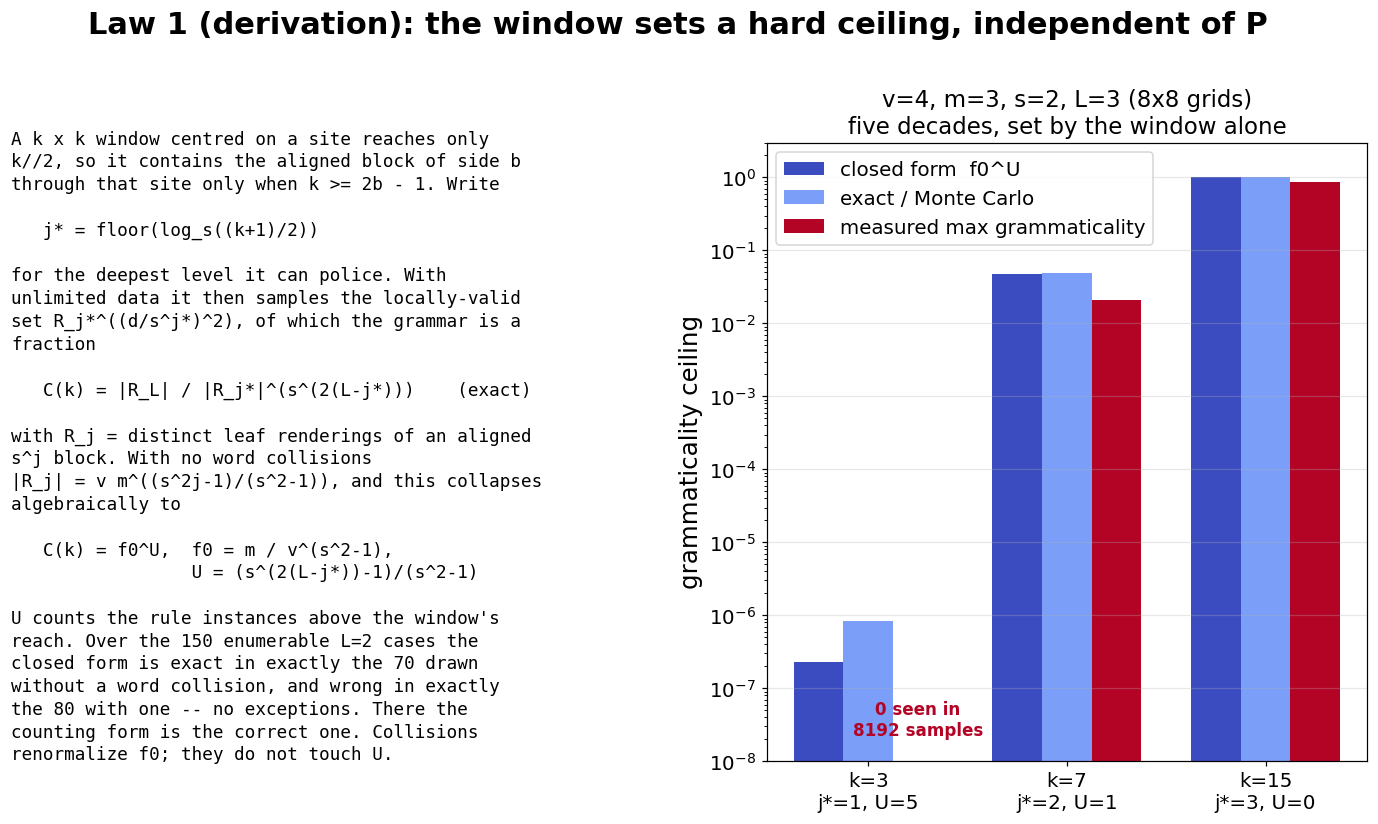

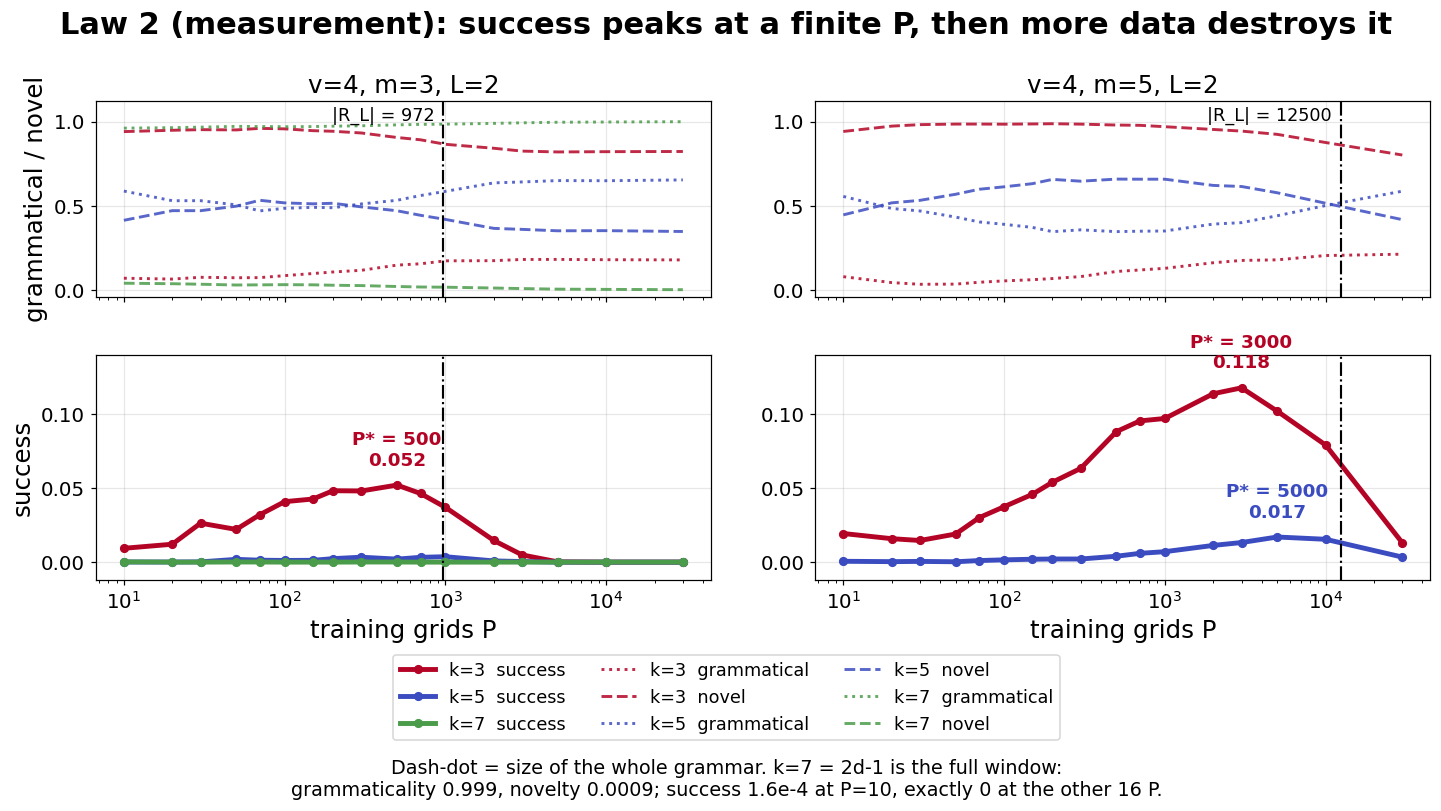

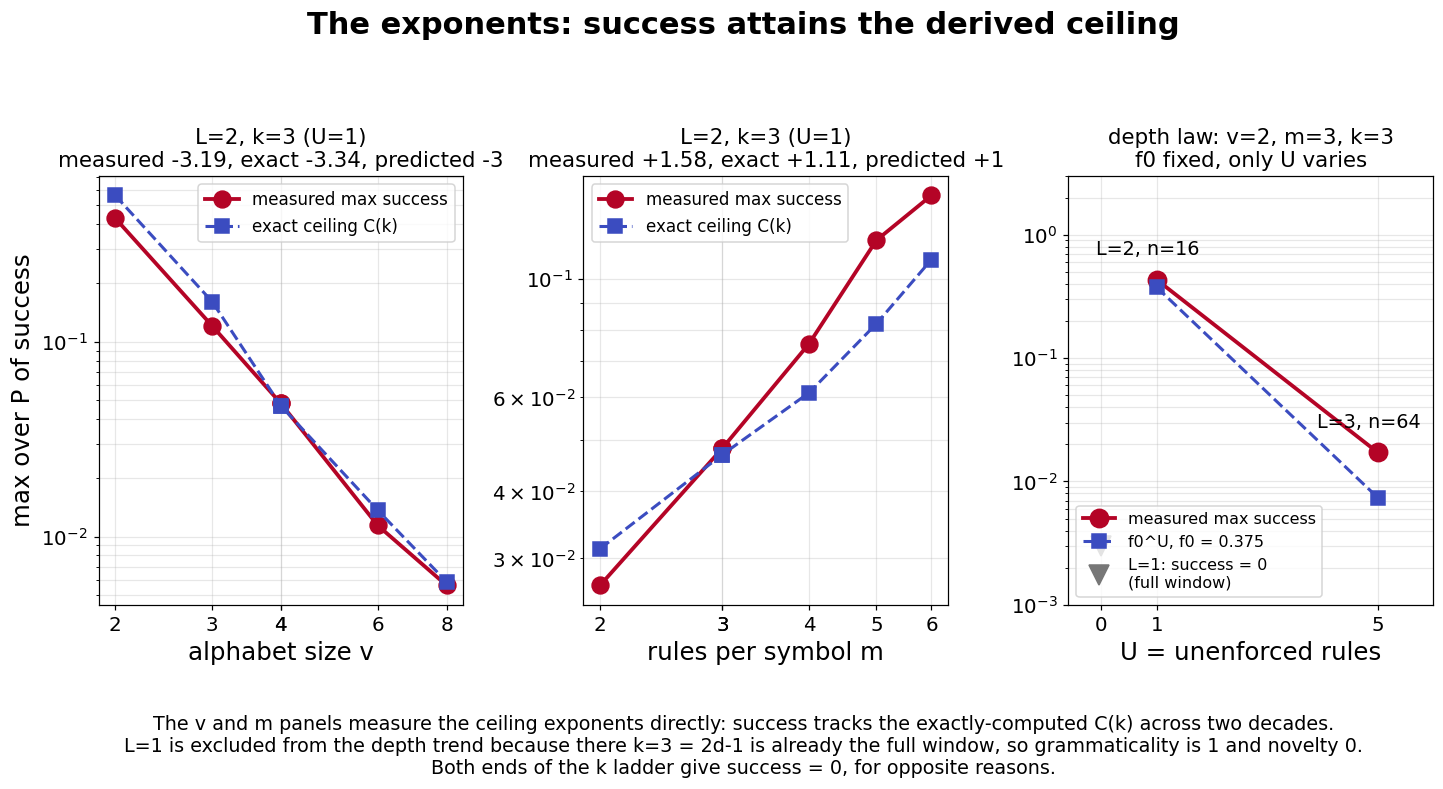

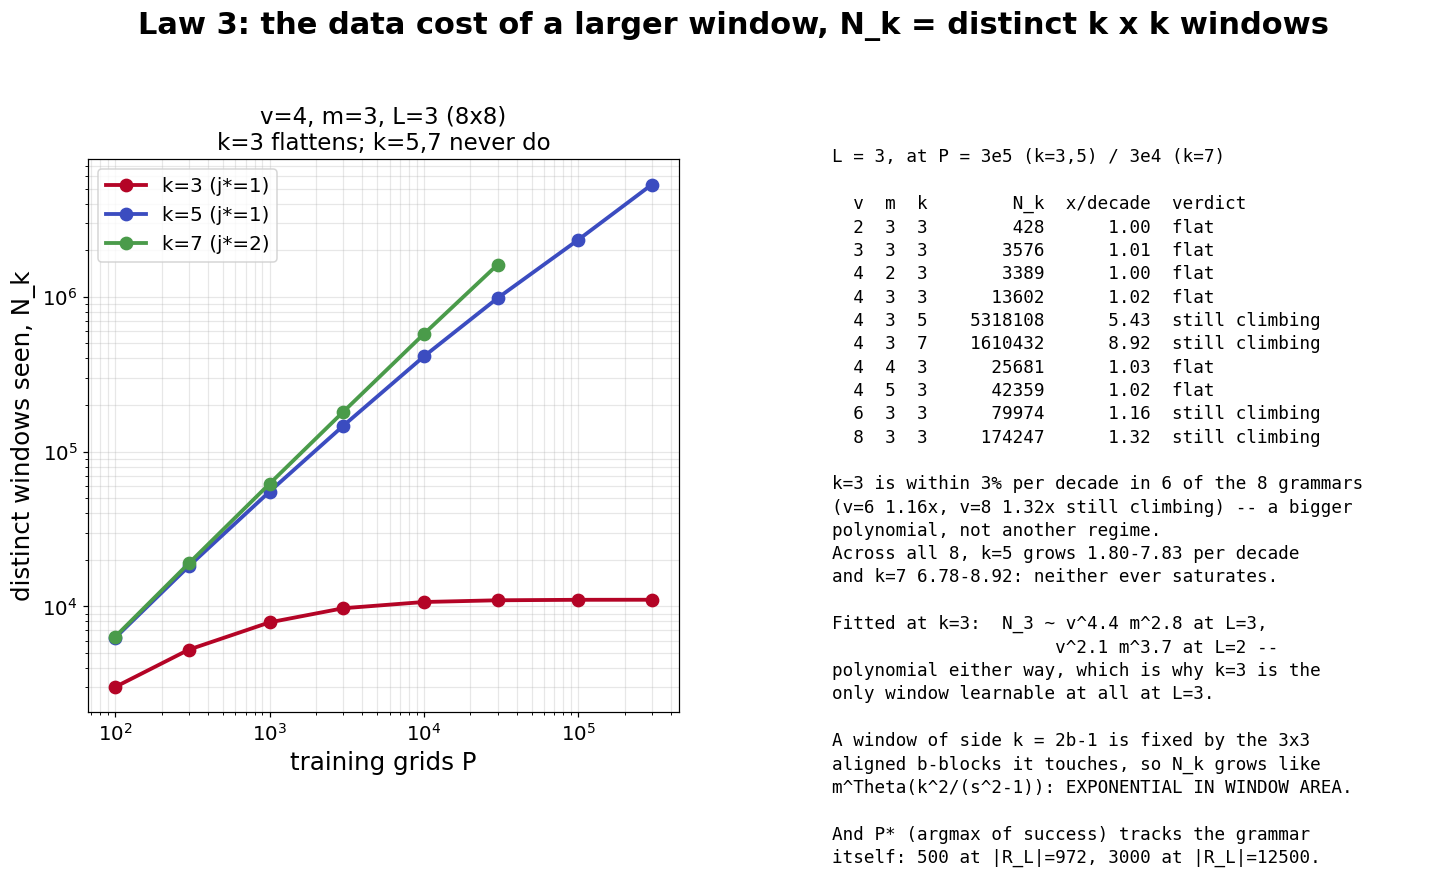

In [9]:
import io

from IPython.display import Image, display


class Inline:
    """Stand-in for PdfPages so the deck's page functions render in the notebook.

    Encodes the PNG by hand rather than calling plt.show() or display(fig):
    build_rhm_slides sets the Agg backend at import, under which plt.show() is a
    silent no-op and no Figure png formatter is registered, so either one would
    leave the notebook with no figures in it.
    """

    def savefig(self, fig):
        buf = io.BytesIO()
        fig.savefig(buf, format='png', dpi=110, bbox_inches='tight')
        display(Image(data=buf.getvalue()))


sh = Inline()
B.page_ceiling(sh, D)     # law 1: the derived ceiling, five decades, independent of P
B.page_phase(sh, D)       # the measured phase diagram and the novelty collapse
B.page_exponents(sh, D)   # the v, m and depth exponents against prediction
B.page_cost(sh, D)        # law 2: N_k(P) and what it costs to fill the table

## Example traces and the tokenization

What the machine actually emits, with the bottom-up parse of each grid. Built live (not
read from the sweeps) at `v=4, s=2, L=3, m=3, rule seed 1000`, `P=600` training grids.

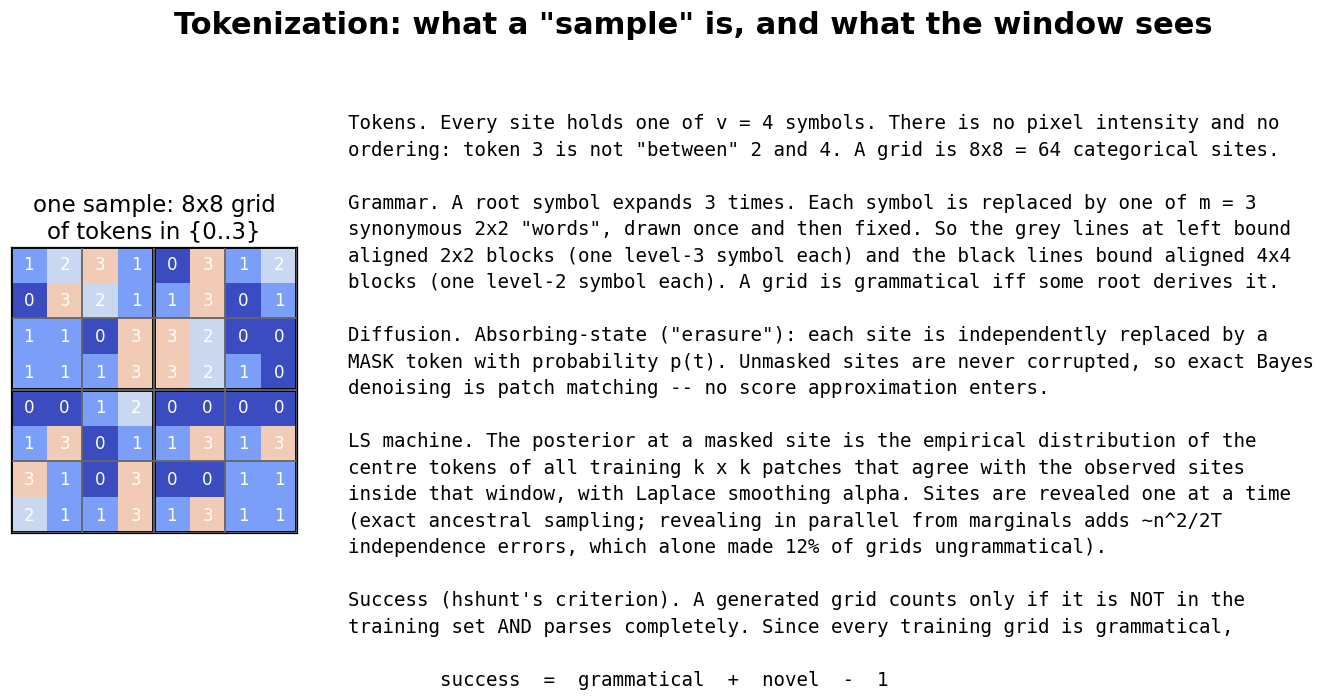

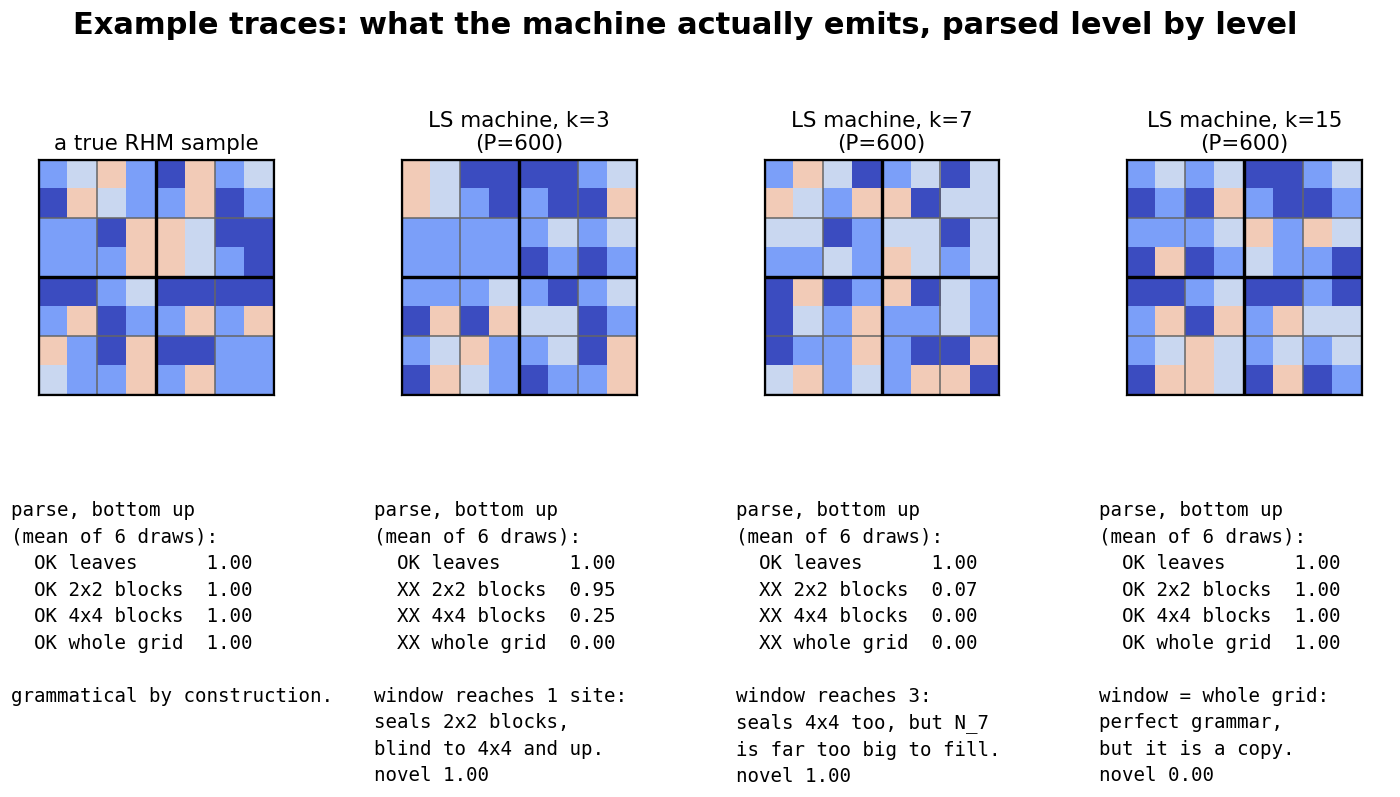

In [10]:
import torch

from src.utils.discrete_score import ScheduledDiscreteScoreMachine, linear_mask_schedule
from src.utils.random_hierarchy import RandomHierarchyModel2D
from src.utils.rhm_grammar import evaluate_samples
from src.utils.rhm_sampling import PatchCountDiscreteScoreMachine

rhm = RandomHierarchyModel2D(v=4, s=2, L=3, m=3, seed=1000)
train, _ = rhm.sample(600, seed=4242)
traces = [('a true RHM sample', train[0], [1., 1., 1., 1.], 'grammatical by construction.')]
notes = {3: 'window reaches 1 site:\nseals 2x2 blocks,\nblind to 4x4 and up.',
         7: 'window reaches 3:\nseals 4x4 too, but N_7\nis far too big to fill.',
         15: 'window = whole grid:\nperfect grammar,\nbut it is a copy.'}
for k, note in notes.items():
    mach = PatchCountDiscreteScoreMachine(train, vocab_size=rhm.v, kernel_size=k,
                                          alpha_smooth=1e-3, device='cpu',
                                          block_align=2 if k < 15 else 1, pad_mode='outside')
    sm = ScheduledDiscreteScoreMachine(mach, vocab_size=rhm.v, grid_size=rhm.grid_size,
                                       default_time_steps=128, mask_schedule=linear_mask_schedule,
                                       mask_token=rhm.v, reveal_one=True)
    gen = torch.Generator(device='cpu').manual_seed(11 + k)
    out = sm.sample(n_samples=6, device='cpu', generator=gen).cpu().numpy()
    ev = evaluate_samples(rhm, train, out)
    traces.append((f'LS machine, k={k}\n(P=600)', out[0],
                   list(reversed(ev['level_parse_fraction'])),
                   note + f'\nnovel {ev["novel"]:.2f}'))

B.page_tokenization(sh, rhm, train[0])
B.page_traces(sh, rhm, traces)

## Comparison against the previous best on the same eval

**There is none.** This is the repo's first measurement of RHM sampling complexity under
the novel-and-grammatical criterion. Searching the repo for prior numbers on this eval:

- `notebooks/random_hierarchy_discrete_score_demo.ipynb` and
  `notebooks/auto_scaling_score_machines.ipynb` run the LS machine on the RHM but score
  only reconstruction/likelihood-style quantities; neither parses a generated grid against
  the grammar, and neither checks novelty, so no number there is comparable.
- The grammar oracle (`src/utils/rhm_grammar.py`), the phase-aware patch-count machine
  (`src/utils/rhm_sampling.py`) and the exact one-site-at-a-time sampler
  (`reveal_one` in `src/utils/discrete_score.py`) were all written for this measurement.

The internal baselines this run *does* beat, on this eval, are the two geometry choices the
repo's own `LocalDiscreteScoreMachine` makes. At `v=4, s=2, L=3, m=3, k=3, P=1e5`, the
fraction of aligned 2x2 blocks that parse is

In [11]:
rows = []
for f, lab in [('A1_window.json', 'phase-aware, edge-aware (this work)'),
               ('A2_pooled.json', 'offsets pooled, edge-aware'),
               ('A3_repo_machine.json', 'offsets pooled, zero-padded (repo geometry)')]:
    rs = [r for r in load(f) if r['k'] == 3 and not r.get('skipped')]
    g = agg(rs, lambda r: r['P'], [lambda r: r['level_parse_fraction'][2],
                                   lambda r: r['level_parse_fraction'][1],
                                   lambda r: r['grammatical'], lambda r: r['novel']])
    P = max(g)
    rows.append([lab, P] + g[P])
table(['machine geometry', 'P', '2x2 ok', '4x4 ok', 'gram', 'novel'], rows)
print('\nSame data, same window, same sampler: pooling the s x s offsets costs a factor ~3 in')
print('the only level a 3x3 window can learn, and zero-padding costs another ~1.5. Neither')
print('changes the asymptotics -- both leave grammaticality at 0 -- but any future')
print('RHM measurement with this machine should use block_align=s and pad_mode=outside.')

                           machine geometry       P  2x2 ok     4x4 ok  gram  novel
-----------------------------------------------------------------------------------
        phase-aware, edge-aware (this work)  100000   0.995     0.1252     0      1
                 offsets pooled, edge-aware  100000   0.348   0.006592     0      1
offsets pooled, zero-padded (repo geometry)  100000   0.241  0.0009766     0      1

Same data, same window, same sampler: pooling the s x s offsets costs a factor ~3 in
the only level a 3x3 window can learn, and zero-padding costs another ~1.5. Neither
changes the asymptotics -- both leave grammaticality at 0 -- but any future
RHM measurement with this machine should use block_align=s and pad_mode=outside.


## The scaling law

Combining the two legs. Success `>= eps` requires `U = O(1)`, i.e. `s^(2(L-j*)) = O(1)`,
i.e. the window must scale with the whole grid: `k = Theta(d) = Theta(sqrt(n))`. But then
the patch table has `|R_j*| = v m^(Theta(n/(s^2-1)))` entries, and `P` must fill it while
staying below the memorization point `|R_L|` -- and at `k = 2d-1` those two coincide
exactly, so the interval where success `> 0` closes. Hence

$$\boxed{\;P^* \;=\; v\,m^{\Theta\!\left(n/(s^2-1)\right)} \;=\; \exp(\Theta(n)),
\qquad n = s^{2L}\;}$$

and under the joint criterion there is no finite `P` at all. At fixed `k`,

$$\text{success} \;\sim\; f_0^{\,(n/a - 1)/(s^2-1)},\qquad a = s^{2j^*} \approx
\left(\tfrac{k+1}{2}\right)^2 \quad\Longrightarrow\quad \ln\frac{1}{\text{success}}
= \Theta\!\left(\frac{n}{k^2}\right).$$

**Why this matters beyond the RHM.** The obstruction is compositional, not statistical. One
window cannot police two scales at once, and widening it to reach the second scale costs
exponentially. A *hierarchy* of windows -- a 3x3 machine whose output feeds a second 3x3
machine acting on inferred level-1 symbols -- would police scale `s^2` at the cost of two
tables of size `|R_1|`, i.e. **polynomial** instead of exponential. That is the natural next
experiment, and it is the RHM-side version of the multilayer-LS (MLS) thread.

### Reproducing

```bash
sbatch scripts/rhm_sweep2.sbatch      # the generation sweeps (GPU, ~6 h)
sbatch scripts/rhm_ceiling.sbatch     # the derivation, run as code (CPU, ~1 h)
sbatch scripts/rhm_counts.sbatch      # N_k(P) (CPU, ~4 h)
python scripts/build_rhm_slides.py --results results/rhm_sampling/2026-11-02 \
    --out results/rhm_sampling/2026-11-02/rhm_sampling_complexity_slides.pdf
```

### Known gaps

- The `L=4` endpoints of the ceiling table are missing: that stage of job 50861297 was
  OOM-killed trying to enumerate `R_3`. The `L=1,2,3` tables all wrote first, and the
  depth law is already pinned by three points, so this is an extra confirmation rather
  than a hole in the argument.
- The measured ceiling runs a bounded factor (~1.2-2.7) above the independent-blocks
  prediction, from cross-block correlation carried by overlapping windows. It renormalizes
  `f0` and not `U`, so the asymptotics are unaffected, but it is not quantified.